<a href="https://colab.research.google.com/github/francescaarrusm/5685052---DataScience-GenAI-Submissions/blob/main/W7_Sem_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA)
In this exercise, you will explore a salary dataset (`EDA-DP.csv`) from the Week 7 Seminar Resources on myWBS. Work through the tasks in order. The setup cell below imports the libraries and allows you to upload the dataset.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving EDA-DP.csv to EDA-DP.csv


**Task 1 — Load the data.** Read `EDA-DP.csv` into a pandas DataFrame and display the first few rows.

In [32]:
df = pd.read_csv('EDA-DP.csv')
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,202730,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,92118,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,130500,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,96000,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,190000,USD,190000,US,0,US,M


**Task 2 — Dataset size.** Find the number of rows and columns in the dataset.

In [33]:
df.shape

(16534, 11)

**Task 3 — Dataset structure.** Inspect the column names, data types, and number of non-missing values.

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary              16534 non-null  int64 
 5   salary_currency     16534 non-null  object
 6   salary_in_usd       16534 non-null  int64 
 7   employee_residence  16534 non-null  object
 8   remote_ratio        16534 non-null  int64 
 9   company_location    16534 non-null  object
 10  company_size        16534 non-null  object
dtypes: int64(4), object(7)
memory usage: 1.4+ MB


**Task 4 — Missing data.** Check how many missing values there are in each column.

In [35]:
df.isnull().sum()

,0
work_year,0
experience_level,0
employment_type,0
job_title,0
salary,0
salary_currency,0
salary_in_usd,0
employee_residence,0
remote_ratio,0
company_location,0


**Task 5 — Missing-data percentages.** Calculate the percentage of missing values for each column. Think about how you would handle missing data if you found any.

In [36]:
df.isnull().sum()/len(EDA)*100

,0
work_year,0.0
experience_level,0.0
employment_type,0.0
job_title,0.0
salary,0.0
salary_currency,0.0
salary_in_usd,0.0
employee_residence,0.0
remote_ratio,0.0
company_location,0.0


**Task 6 — Duplicates.** Find how many rows are exact duplicates and how many are not. Would identical records necessarily be errors in this dataset?

In [37]:
df.duplicated().value_counts()

,count
False,10113
True,6421


**Task 7 — Summary statistics.** Produce descriptive statistics for the numerical columns. What do the distributions tell you? Note that `salary` may use different currencies, whereas `salary_in_usd` is comparable across records.

In [38]:
df.describe()

,work_year,salary,salary_in_usd,remote_ratio
count,16534.000000,1.653400e+04,16534.000000,16534.000000
mean,2023.226866,1.637270e+05,149686.777973,32.003750
std,0.713558,3.402057e+05,68505.293156,46.245158
min,2020.000000,1.400000e+04,15000.000000,0.000000
25%,2023.000000,1.017630e+05,101125.000000,0.000000
50%,2023.000000,1.422000e+05,141300.000000,0.000000
75%,2024.000000,1.872000e+05,185900.000000,100.000000
max,2024.000000,3.040000e+07,800000.000000,100.000000


### Visualising the Data

**Task 8 — Bar chart.** Create a bar chart comparing the **average salary in USD** across experience levels (`EN`, `MI`, `SE`, `EX`). Add clear axis labels and a title. Which group has the highest average?

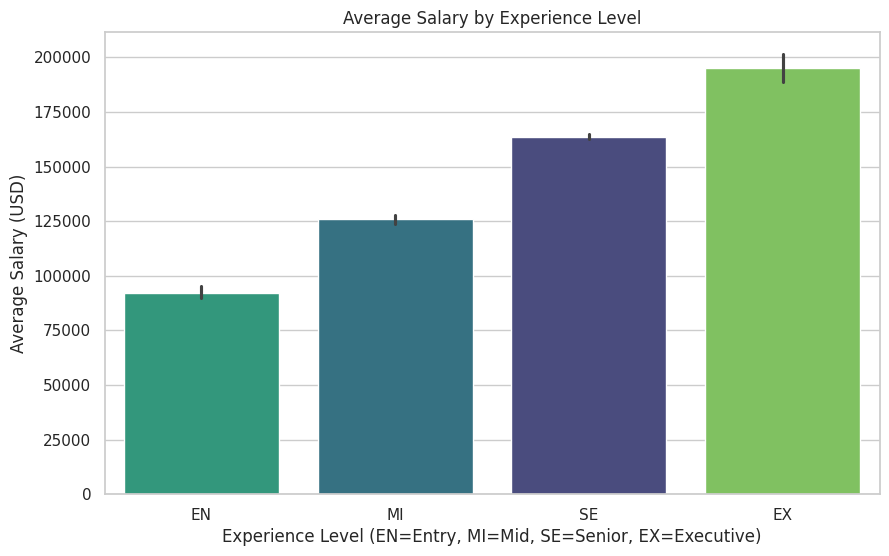

In [40]:
plt.figure(figsize=(10, 6))

# Experience Level vs Salary
sns.barplot(data=df, x='experience_level', y='salary_in_usd',
            order=['EN', 'MI', 'SE', 'EX'], palette='viridis', hue='experience_level', legend=False)
plt.title('Average Salary by Experience Level')
plt.ylabel('Average Salary (USD)')
plt.xlabel('Experience Level (EN=Entry, MI=Mid, SE=Senior, EX=Executive)')
plt.show()

**Task 9 — Scatter plot.** Make a scatter plot of `work_year` against `salary_in_usd`. Label the axes. What patterns do you notice? Are any points difficult to distinguish because they overlap?

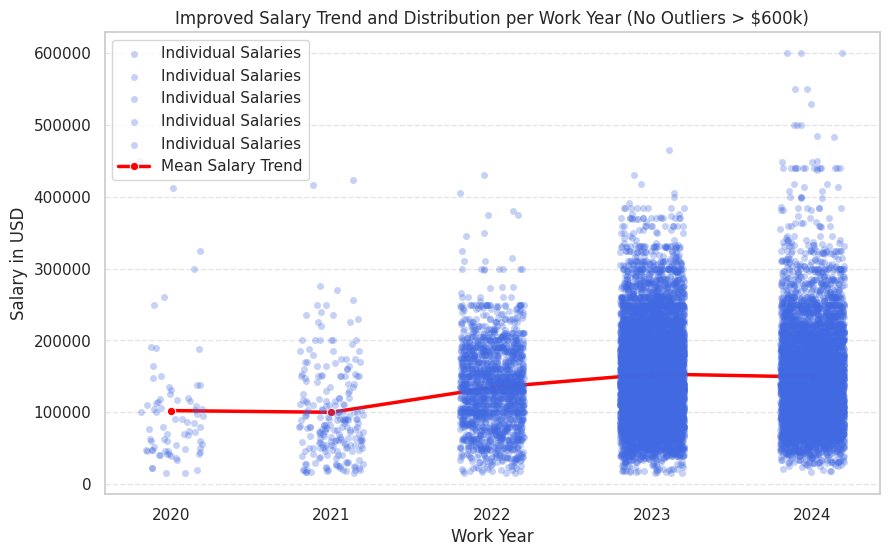

In [41]:
plt.figure(figsize=(10, 6))

# Filter out outliers above 600,000 USD
filtered_EDA = df[df['salary_in_usd'] <= 600000]

sns.stripplot(data=filtered_EDA, x='work_year', y='salary_in_usd', color='royalblue', alpha=0.3, jitter=0.2, label='Individual Salaries')

mean_salaries = filtered_EDA.groupby('work_year')['salary_in_usd'].mean().reset_index()
sns.lineplot(data=mean_salaries, x=mean_salaries.index, y='salary_in_usd', color='red', linewidth=2.5, marker='o', label='Mean Salary Trend')

plt.xlabel('Work Year')
plt.ylabel('Salary in USD')
plt.title('Improved Salary Trend and Distribution per Work Year (No Outliers > $600k)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Task 10 — Distribution.** Plot the distribution of `salary_in_usd`. Does it look approximately normal, skewed, or something else? Are there extreme values?

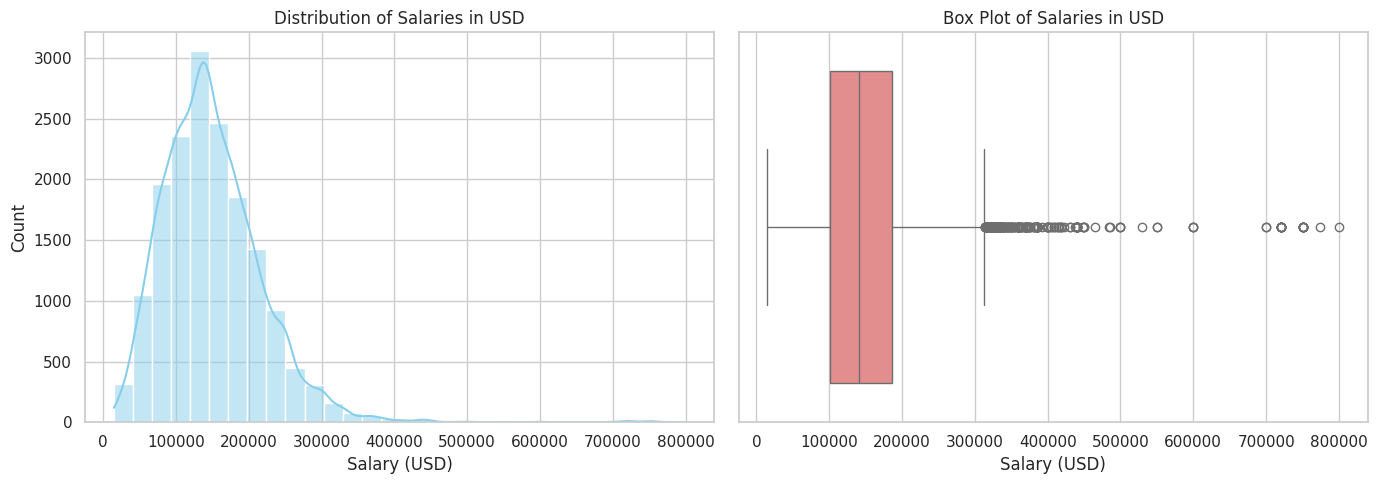

In [42]:
plt.figure(figsize=(14, 5))

# Histogram
plt.subplot(1, 2, 1)
sns.histplot(data=df, x='salary_in_usd', kde=True, bins=30, color='skyblue')
plt.title('Distribution of Salaries in USD')
plt.xlabel('Salary (USD)')

# Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='salary_in_usd', color='lightcoral')
plt.title('Box Plot of Salaries in USD')
plt.xlabel('Salary (USD)')

plt.tight_layout()
plt.show()

**Task 11 — Pairwise relationships.** Visualize pairwise relationships among `salary_in_usd`, `work_year`, and `remote_ratio`, including distributions of the individual variables.

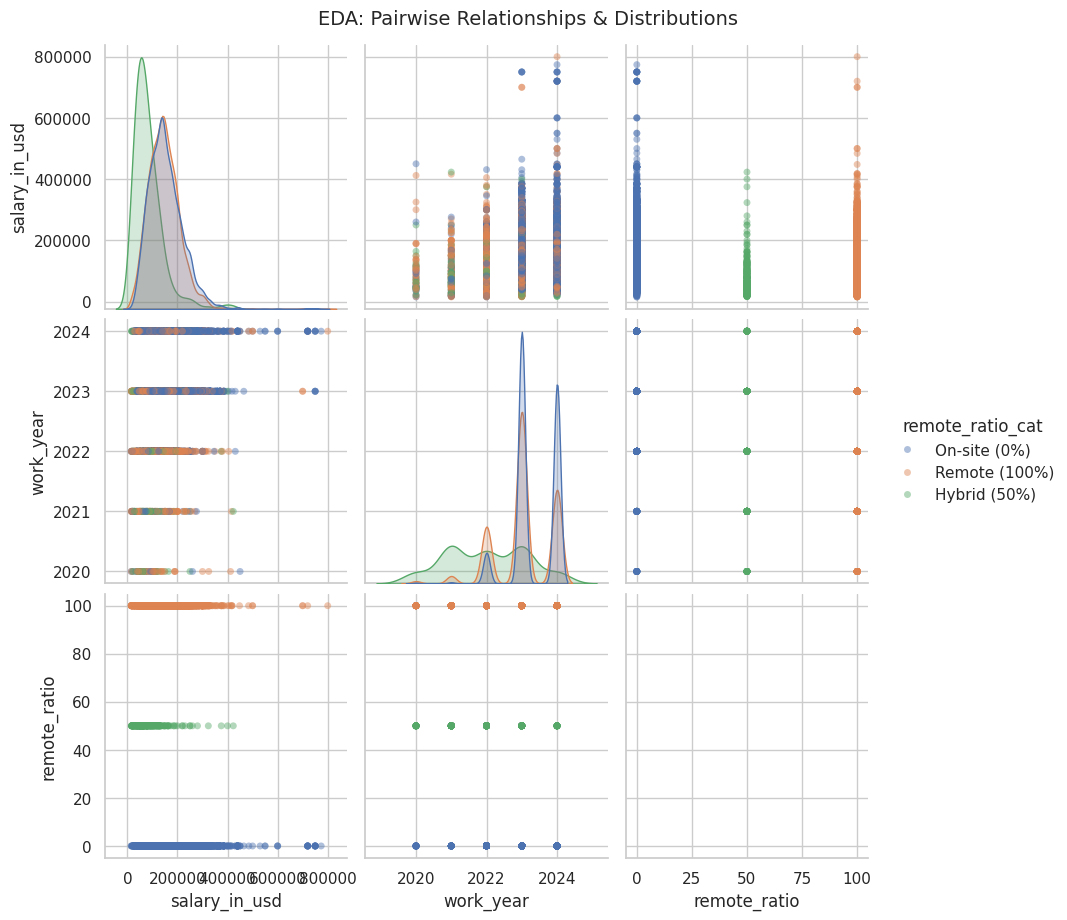

In [43]:
cols = ["salary_in_usd", "work_year", "remote_ratio"]
EDA = df[cols].dropna().copy()

# Optional: convert discrete variables to clean labels for clearer legends/ticks
EDA["remote_ratio_cat"] = EDA["remote_ratio"].map(
    {0: "On-site (0%)", 50: "Hybrid (50%)", 100: "Remote (100%)"}
)

sns.set_theme(style="whitegrid")

g = sns.pairplot(
    EDA,
    vars=cols,
    hue="remote_ratio_cat",  # color points by remote work mode; remove if unwanted
    diag_kind="kde",  # "kde" or "hist" for individual distributions on the diagonal
    plot_kws={"alpha": 0.45, "s": 25, "edgecolor": "none"},
    diag_kws={"fill": True, "common_norm": False},
    height=3.0,
)

g.figure.suptitle(
    "EDA: Pairwise Relationships & Distributions", y=1.02, fontsize=14
)
plt.show()

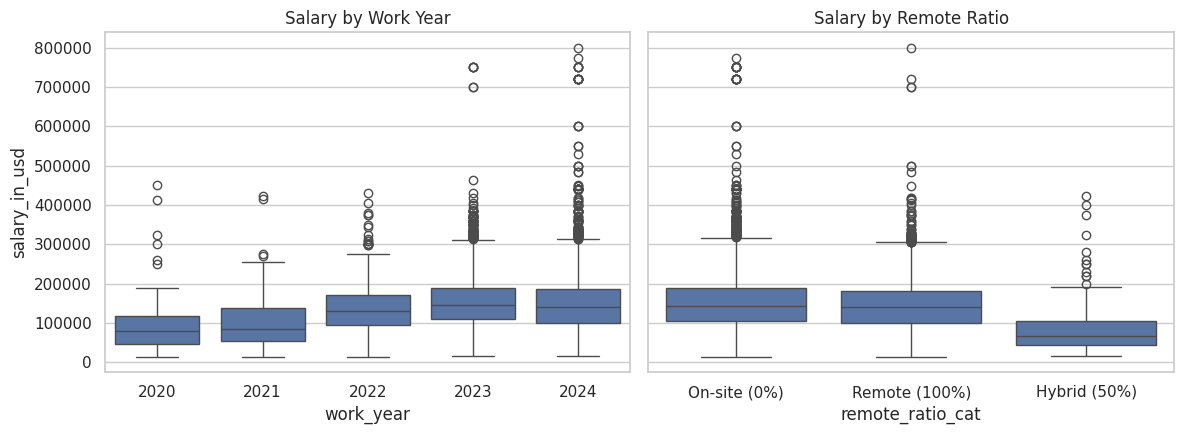

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

sns.boxplot(data=EDA, x="work_year", y="salary_in_usd", ax=axes[0])
axes[0].set_title("Salary by Work Year")

sns.boxplot(data=EDA, x="remote_ratio_cat", y="salary_in_usd", ax=axes[1])
axes[1].set_title("Salary by Remote Ratio")

plt.tight_layout()
plt.show()

**Task 12 — Remove a column.** Remove the original-currency `salary` column while retaining `salary_in_usd`, then inspect the updated DataFrame. Why might you choose to keep one salary column rather than both?

In [47]:
df = df.drop(columns=["salary"], errors="ignore")
print("Columns:", df.columns.tolist())
print("\nShape:", df.shape)
display(df.head())
df.info()

Columns: ['work_year', 'experience_level', 'employment_type', 'job_title', 'salary_currency', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size']

Shape: (16534, 10)


,work_year,experience_level,employment_type,job_title,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,USD,202730,US,0,US,M
1,2024,SE,FT,AI Engineer,USD,92118,US,0,US,M
2,2024,SE,FT,Data Engineer,USD,130500,US,0,US,M
3,2024,SE,FT,Data Engineer,USD,96000,US,0,US,M
4,2024,SE,FT,Machine Learning Engineer,USD,190000,US,0,US,M


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16534 entries, 0 to 16533
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           16534 non-null  int64 
 1   experience_level    16534 non-null  object
 2   employment_type     16534 non-null  object
 3   job_title           16534 non-null  object
 4   salary_currency     16534 non-null  object
 5   salary_in_usd       16534 non-null  int64 
 6   employee_residence  16534 non-null  object
 7   remote_ratio        16534 non-null  int64 
 8   company_location    16534 non-null  object
 9   company_size        16534 non-null  object
dtypes: int64(3), object(7)
memory usage: 1.3+ MB


In [48]:
df = EDA.drop(['salary', 'salary_currency', 'employee_residence', 'company_location'], axis=1, errors='ignore')
df.head()

,salary_in_usd,work_year,remote_ratio,remote_ratio_cat
0,202730,2024,0,On-site (0%)
1,92118,2024,0,On-site (0%)
2,130500,2024,0,On-site (0%)
3,96000,2024,0,On-site (0%)
4,190000,2024,0,On-site (0%)


**Reflection.** What have you learned about the salary dataset? Which additional checks or visualizations would be useful before building a machine learning model?